<img src="headerbox.png">


<h1>The hydrogen molecule-ion</h1>

---

<h4><b>Developed by Audun Skau Hansen <a href="mailto:a.s.hansen@kjemi.uio.no">✉️</a> at the Department of Chemistry, The Hylleraas Centre for Quantum Molecular Sciences, University of Oslo (2021)</h4>
    
If you have trouble running the notebook, please install BraketLab: 

In [ ]:
pip install braketlab bubblebox --force-reinstall

In [2]:
# import modules for this notebook

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

import braketlab as bk

In [ ]:
#gallery = 0


p = bk.basisbank.get_gto(20.0, 0,0, position = (0,0,0))
for l in range(1,3):
    for m in range(-l, l+1):
        print(l,m)
        p += bk.basisbank.get_gto(20.0, l,m, position = (0,-l,m))
        
p.view()

## Overview

In order to get a more hands-on feel for concepts such as molecular orbitlas, linear combinations of atomic orbitals (LCAO) and Hartree-Fock theory, we'll have a look at the case of H$_2^+$ (one-electron Hydrogen molecule). Note that the following derivation can be done by simply by pen and paper, as presented in the compendium. In the following, we shall instead use BraketLab to do the same. This has the downside that our integrals are only approximately computed, but on the upside it can easily be extended beyond the H$_2^+$-case by adding more terms to the hamiltonian and wavefunction.

A good strategy for learning is to draw the system, write down its Hamiltonian, and then determine on how to proceed further.

The system consists of two nucleis A and B, situated at coordinates $\mathbf{R}_A$ and $\mathbf{R}_B$, each containing a single proton. They are separated by a distance $\mathbf{R} = \vert \mathbf{R}_A - \mathbf{R}_B \vert$. A single electron moves around in the potential of the nucleis. Run the cell beneath for a visualization.

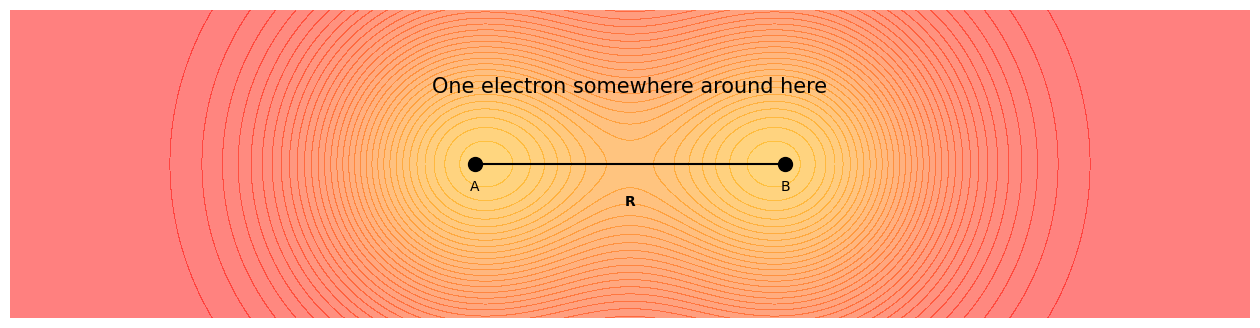

In [3]:
plt.figure(figsize=(16,4))
tx, ty = 4*np.linspace(-1,1, 1001), np.linspace(-1,1,401)
plt.contourf(tx,ty,np.exp(-.9*((tx[None,:]-1)**2 + (ty[:, None])**2  ))+np.exp(-.9*((tx[None,:]+1)**2 + (ty[:, None])**2  )), levels = np.linspace(0,1.5,50), cmap = "autumn", alpha = .5)
plt.plot([-1, 1], [0,0], "o-", markersize = 10, color = (0,0,0))
plt.text(-1, -.15, "A", ha = "center", va = "center")
plt.text(1, -.15, "B", ha = "center", va = "center")
plt.text(0, -.25, "$\mathbf{R}$", ha = "center", va = "center")
plt.text(0,.5, "One electron somewhere around here", ha = "center", va = "center", fontsize = 15)
plt.axis("off")
plt.show()


Our job as quantum chemists is now to determine the distribution of the electron around the nucleis at low temperatures. Specifically, we are looking for the ground state wavefunction of the system, which in this case is the eigenstate with the lowest eigenvalue of the Hamiltonian:

\begin{equation}
   \hat{H} = -\frac{1}{2}\nabla^2 - \frac{1}{\vert \boldsymbol{r}-\boldsymbol{R}_A \vert}
             - \frac{1}{\vert \boldsymbol{r}-\boldsymbol{R}_B \vert} + \frac{1}{R}
\end{equation}

This Hamiltonian can be constructed using BraketLab in the following way:

In [ ]:
R = 1.0
R_A = np.array([-R/2.0,0,0])
R_B = np.array([ R/2.0,0,0])

T = bk.get_kinetic_operator()
V_A = bk.get_onebody_coulomb_operator(R_A)
V_B = bk.get_onebody_coulomb_operator(R_B)

H = T  + V_A  + V_B
H

Solving this equation for various distances of $\mathbf{R}$ will allow us to determine wether or not the system bonds, and at what distance it potentially has its equilibrium. Furthermore we may derive the ionization energy (how much does it take to free the electron) and the affinity (how much does the system gain by capturing another electron.

An efficient tool in dealing with these matters is the variational principle. That is, if we can express our wavefunction in a parameterized way, say
\begin{equation}
\vert \Psi  \rangle = \Psi_{\text{trial}}(\{C \}, \mathbf{x} ),
\end{equation}
where $\{C \}$ is some set of parameters, then we can minimize the variational energy
\begin{equation}
E_0 \leq E[\{C \}] = \frac{\langle \Psi_{\text{trial}} \vert \hat{H} \vert \Psi_{\text{trial}} \rangle}{\langle \Psi_{\text{trial}} \vert  \Psi_{\text{trial}} \rangle} 
\end{equation}
in order to approximate the ground state within the available space spanned by $\Psi_{\text{trial}}(\{C \}, \mathbf{x} )$. In plain words, we just (skillfully) guess for the best possible wavefunction, as determined by $C$.

So what is a good starting guess? When $\mathbf{R}$ is sufficiently large, the two protons reduces to two independent subsystems. From this observation we may guess that the more proximal system is not that different, thus motivating the use of hydrogen-like basis functions like the two ground-state $1s$-functions. We pick the ground states, since they have the lowest energy, which makes sense in the context of the variational method. Let's now construct these states using BraketLab:

In [ ]:
R = 4 # <- distance between the two H2 atoms
n, l, m = 1,0,0 # <- quantum numbers of orbitals

chi_1 = bk.basisbank.get_hydrogen_function(n,l,m, position = np.array([-R/2,0,0]))
chi_2 = bk.basisbank.get_hydrogen_function(n,l,m, position = np.array([ R/2,0,0]))




Inspecting them visually yields something like

In [ ]:
t = np.linspace(-5,5,301)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (9,4))

ax1.contour(t, t, chi_1(t[None,:],t[:, None],0), cmap = "GnBu", alpha = 1)
ax1.plot(t, 4*chi_1(t,0,0), color = (.01,.1,.15))

ax2.contour(t, t, chi_2(t[None,:],t[:, None],0), cmap = "RdGy", alpha = 1)
ax2.plot(t, 4*chi_2(t,0,0), color = (.4,.05,.05))
plt.show()

You may form any linearcombination using coefficents $C_{1s_A}$ and $C_{1s_B}$, so that
\begin{equation}
\phi_p(\mathbf{x}) = \chi_{1s_A}(\mathbf{x})C_{1s_A} + \chi_{1s_B}(\mathbf{x})C_{1s_B}
\end{equation}
We shall refer to $\phi_p(\mathbf{x})$ as a *molecular orbital* (MO), and $\chi_{1s_A}(\mathbf{x})$ as an *atomic orbital* (AO). Thus, molecular orbitals will be formed as linear combination of atomic orbitals (LCAO).



## Determining the wavefunction

In order to determine the coefficents of the orbitals, we'll find that we have to solve a generalized eigenvalue problem
\begin{equation}
    \mathbf{HC} = \mathbf{SC\varepsilon},
\end{equation}
where the overlap matrix is
\begin{equation}
    \mathbf{S} =
    \begin{pmatrix}
       \langle \chi_{1\text{s}_A} \vert \chi_{1\text{s}_A} \rangle &
       \langle \chi_{1\text{s}_A} \vert \chi_{1\text{s}_B} \rangle \\ 
       \langle \chi_{1\text{s}_B} \vert \chi_{1\text{s}_A} \rangle &
       \langle \chi_{1\text{s}_B} \vert \chi_{1\text{s}_B} \rangle 
    \end{pmatrix}
    =
    \begin{pmatrix}
       1 & S \\
       S & 1
    \end{pmatrix},
\end{equation}
and the Hamiltonian matrix is
\begin{equation}
   \mathbf{H} =
    \begin{pmatrix}
       \langle \chi_{1\text{s}_A} \vert \hat{H} \vert \chi_{1\text{s}_A} \rangle &
       \langle \chi_{1\text{s}_A} \vert \hat{H} \vert\chi_{1\text{s}_B} \rangle \\ 
       \langle \chi_{1\text{s}_B} \vert \hat{H} \vert \chi_{1\text{s}_A} \rangle &
       \langle \chi_{1\text{s}_B} \vert \hat{H} \vert \chi_{1\text{s}_B} \rangle 
    \end{pmatrix}
    =
    \begin{pmatrix}
       a & b \\
       b & a
    \end{pmatrix}.
\end{equation}
The orbital coefficients $C$ and the orbital eigenvalues $\epsilon$ are the unknowns we have to find through diagonalization.

However, we cannot directly diagonalize $\mathbf{H}$ due to the presence of $\mathbf{S}$ in the above equation. Rather, we have to obtain $\mathbf{C}$ in steps: first, we compute the *Löwdin orthogonalization matrix* from the eigenvalues and eigenvectors of $\mathbf{S}$:
\begin{equation}
S \mathbf{v}_s = \epsilon_s \mathbf{v}_s.
\end{equation}
The orthogonalization matrix has elements
\begin{equation}
\big{(}\mathbf{S}^{-\frac{1}{2}}\big{)}_{ij} = \sum_k   (\mathbf{v}_s)_{ki} \frac{1}{\sqrt{(\epsilon_s)_k}} (\mathbf{v}_s)_{kj}.
\end{equation}
With Python, this is implemented by:

In [ ]:
def get_lowdin_matrix(S):
    e_s, v_s = np.linalg.eigh(S)
    s_12 = v_s.T.dot(np.diag(e_s**-.5).dot(v_s)) # <- compute S^{-.5}
    return s_12 

We then proceed by multiplying the generalized eigenvalue equation by $\mathbf{S}^{-\frac{1}{2}}$ from the left:
\begin{equation}
    \mathbf{S}^{-\frac{1}{2}} \mathbf{HC} = \mathbf{S}^{-\frac{1}{2}} \mathbf{SC\varepsilon},
\end{equation}
which yields
\begin{equation}
    \mathbf{S}^{-\frac{1}{2}} \mathbf{HC} = \mathbf{S}^{\frac{1}{2}} \mathbf{C\varepsilon}.
\end{equation}
We may invoke the identity $\mathbb{1} = \mathbf{S}^{-\frac{1}{2}} \mathbf{S}^{\frac{1}{2}}$ to find
\begin{equation}
    \mathbf{S}^{-\frac{1}{2}} \mathbf{H}\big{(} \mathbf{S}^{-\frac{1}{2}} \mathbf{S}^{\frac{1}{2}} \big{)}\mathbf{C} = \mathbf{S}^{\frac{1}{2}} \mathbf{C\varepsilon}.
\end{equation}
If we now define $\tilde{\mathbf{C}} = \mathbf{S}^{\frac{1}{2}}\mathbf{C}$ and $\mathbf{\tilde{H}} = \mathbf{S}^{-\frac{1}{2}} \mathbf{H}\mathbf{S}^{-\frac{1}{2}}$, the above can be solved as a ordinary eigenvalue problem:
\begin{equation}
     \mathbf{\tilde{H}} \tilde{\mathbf{C}} = \tilde{\mathbf{C}}\mathbf{\varepsilon},
\end{equation}
from which the coefficients are obtained as 
\begin{equation}
     \mathbf{C} =  \mathbf{S}^{-\frac{1}{2}} \tilde{\mathbf{C}}.
\end{equation}

In [ ]:
## Implementing the solution

def get_orbitals(R):
    """
    This function computes orbitals and orbital energies H_2^+ for a given separation R between the nucleis
    """
    
    
    R_A = np.array([-R/2.0,0,0]) # <- position of first Hydrogen nucleus
    R_B = np.array([R/2.0,0,0])  # <- position of second Hydrogen nucleus

    # Construct the Hamiltonian
    T = bk.get_kinetic_operator() # <- kinetic energy of the electron 
    V_A = bk.get_onebody_coulomb_operator(R_A) # <- potential from nucleus A
    V_B = bk.get_onebody_coulomb_operator(R_B) # <- potential from nucleus B
    H = T  + V_A  + V_B # <- total hamiltonian
    
    # Get basis functions
    n,l,m = 1,0,0 # <- quantum numbers of basis functions
    chi_1 = bk.basisbank.get_hydrogen_function(n,l,m, position = R_A)
    chi_2 = bk.basisbank.get_hydrogen_function(n,l,m, position = R_B)
    
    # The following quantities are the ones analytically derived in the compendium (sec. 9.2.1)
    """
    jr = R**-1*(1 - (1+R)*np.exp(-2*R))
    kr = (1+R)*np.exp(-R)
    sr = (1 + R + R**2/3)*np.exp(-R)
    """
    
    # Compute matrix elements
    s_ab = chi_1.bra@chi_2 # <- overlap < chi_A | chi_B >
    h_aa = chi_1.bra@(H*chi_1) + R**-1 # <- Diagonal element in H
    h_ab = chi_2.bra@(H*chi_1) + s_ab*R**-1 #  <- off-diagonal element in H
    
    # Construct matrices
    S = np.array([[1, s_ab],[s_ab, 1]]) # <- the overlap matrix
    H = np.array([[h_aa, h_ab], [h_ab,h_aa]]) # <- The Hamiltonian matrix
    
    # Compute orthogonalizing matrix
    s_12 = get_lowdin_matrix(S)
    
    # Perform the diagonalization (solve generalized eigenvalue problem)
    Htilde = s_12.dot(H.dot(s_12))
    e, ctilde = np.linalg.eigh(Htilde)
    c = s_12.dot(ctilde)
    
    # Sort eigenvalues in order of increasing energy
    ei = np.argsort(e)
    
    # Return results
    return e[ei],c[ei] 

## Obtaining the numerical results

With the above script, we can obtain the coefficents and energy for any inter-nuclear distance $\mathbf{R}$. Let's try it out for $\mathbf{R} = 1.0$ Bohr and plot the orbitals:

In [ ]:
e, c = get_orbitals(1.6)

In [ ]:
phi_1 = c[0,0]*chi_1 + c[1,0]*chi_2

phi_2 = c[0,1]*chi_1 + c[1,1]*chi_2

t = np.linspace(-1,1,301)*6
plt.figure(figsize = (8,8))
plt.title("$\\phi_1$, $\\epsilon_1$ = %.5f" % e[0])
plt.contour(t, t, phi_1(t[None,:],t[:, None],0), cmap = "GnBu", levels = np.linspace(-.5,.5,50))
plt.plot(t, phi_1(t,0,0), color = (.01,.1,.15))
plt.axhline(0, color = (0,0,0), alpha = .3)
plt.show()

plt.figure(figsize = (8,8))
plt.title("$\\phi_2$, $\\epsilon_2$ = %.5f" % e[1])
plt.contour(t, t, phi_2(t[None,:],t[:, None],0), cmap = "RdGy", levels = np.linspace(-1.5,1.5,50))
plt.plot(t, phi_2(t,0,0), color = (.4,.05,.05))
plt.axhline(0, color = (0,0,0), alpha = .3)
plt.show()

From the probability interpretation of the wavefunction it follows that the square of these real-valued functions can be interpeted as the probability of finding the electron in that region. This is shown in the followin figures (the black line has been scaled by a factor of 10 to more clearly show the difference between the two.

In [ ]:
plt.figure(figsize = (8,8))
plt.title("$\\phi_1$, $\\epsilon_1$ = %.5f" % e[0])
plt.contour(t, t, phi_1(t[None,:],t[:, None],0)**2, cmap = "GnBu", levels = np.linspace(-.5,.5,50))
plt.plot(t, 10*phi_1(t,0,0)**2, color = (.01,.1,.15))
plt.axhline(0, color = (0,0,0), alpha = .3)
plt.show()

plt.figure(figsize = (8,8))
plt.title("$\\phi_2$, $\\epsilon_2$ = %.5f" % e[1])
plt.contour(t, t, phi_2(t[None,:],t[:, None],0)**2, cmap = "RdGy", levels = np.linspace(-1.5,1.5,50))
plt.plot(t, 10*phi_2(t,0,0)**2, color = (.4,.05,.05))
plt.axhline(0, color = (0,0,0), alpha = .3)
plt.show()

Notice how the density of the lowest orbital has a net-positive contribution in the region between the nucleis due to the interference, while the excited orbital has a net negative) contribution in this region due to the node. If we now explore how the orbital energies depend on distance $\mathbf{R}$, we find (be a bit patient, this all runs on Monte-Carlo integration).

In [ ]:
Nt = 15 # <- number of distances
energies = np.zeros((2,Nt)) # <- array to store energies
cn = 0 # <- counter
RR = np.linspace(.5, 6.2, Nt) # <- the range of distances 
for R in RR:
    e,c = get_orbitals(R)
    energies[:,cn] = e
    cn+=1

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(RR, energies[0], label = "$\\phi_1$", color = (.1,.5,.75), alpha = .7 )
plt.plot(RR, energies[1], label = "$\\phi_2$", color = (.8,.1,.1), alpha = .7 )
plt.xlabel("$\\mathbf{R}$ / Bohr")
plt.ylabel("Energy / Hartrees")
plt.ylim(-0.6,0.4)
plt.legend()
plt.show()

From the figure above, it becomes apparent that the orbital with the lowest orbital energy in this case has a bonding potential energy due to the presence of a minimum. The excited orbital has no such minimum and simply repels the nucleis apart. We therefore refer to $\phi_1$ as a *bonding orbital*, while $\phi_2$ is reffered to as an *antibonding orbital*.  